**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**08 | Full Development-Cohort Audit**

![Full development-cohort audit workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/08_workflow.svg)

**Objective:** Audit source integrity, eight-class activity coverage and GroupKFold feasibility across all 29 HARTH Development participants before model fitting.

**Dataset:** The pinned HARTH v2.0 recordings for 29 Development participants, excluding the reserved S023 and S032 Test IDs.

**Notebook Scope:** Check the local file inventory, construct label-pure windows and 30 statistical features, and review participant-level class support. Source acquisition can involve large downloads. No classifier or scaler is fitted.

**00. Colab Repository Setup**

In [26]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Project Environment**

In [27]:
# ======================== 01. Imports and Environment ========================

# ---------------------------- 1. Standard Library ----------------------------
import sys
from pathlib import Path

# --------------------- 2. Repository Path Configuration ----------------------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root == root.parent:
        raise RuntimeError("Open this notebook from inside human-movement-intelligence.")
    root = root.parent
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10, 
    figure_dpi=100, figure_size=(9, 4))

# ----------------------- 5. Shared and Study Utilities -----------------------
from core.output_download import download_outputs_from_colab
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, prepare_harth_feature_cohort
from core.data_splitting import audit_group_class_coverage

# -------------------- 6. Output Directory and Setup Summary ------------------
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Research output directory:", output_dir)

Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Check Source Files Before Downloading**

Inspect the cache for all 29 Development recordings without downloading new files. The subsequent cell retrieves missing sources; the reserved S023 and S032 recordings remain excluded.

In [28]:
# ================ 02. Inspect the Development Data Inventory =================

# --------------------- 1. Define Cohort and Source Cache ---------------------
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TASK_CLASSES = tuple(range(1, 9))
data_dir = root / "data/raw/harth_v2"

# ---------------------- 2. Inspect Available Recordings ----------------------
inventory = pd.DataFrame([
    {"subject": subject,
     "locally_cached": (data_dir / f"{subject}.csv").is_file(),
     "local_MiB": round((data_dir / f"{subject}.csv").stat().st_size / 1048576, 2)
     if (data_dir / f"{subject}.csv").is_file() else None}
    for subject in DEVELOPMENT_SUBJECTS
])
assert len(DEVELOPMENT_SUBJECTS) == 29
assert not (set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST)

# --------------------------- 3. Inventory Summary ----------------------------
display(inventory)

print("Development participants:", len(DEVELOPMENT_SUBJECTS))
print("Files not yet cached:", int((~inventory["locally_cached"]).sum()))
print("No source files were downloaded by the inventory cell.")


,subject,locally_cached,local_MiB
0,S006,False,NaN
1,S008,False,NaN
2,S009,False,NaN
3,S010,False,NaN
4,S012,False,NaN
5,S013,False,NaN
6,S014,False,NaN
7,S015,False,NaN
8,S016,False,NaN
9,S017,False,NaN


Development participants: 29
Files not yet cached: 19
No source files were downloaded by the inventory cell.


**03. Prepare the Full Development Feature Cohort**

Retrieve missing public source files as needed, then construct label-pure, two-second windows and 30 statistical features separately for each participant. A previous inventory estimated approximately 775 MiB of additional downloads; the current amount depends on the cache. Undocumented activity codes are recorded without assigning inferred meanings.

In [29]:
# =============== 03. Prepare Development Windows and Features ================

# ---------------------- 1. Prepare Development Features ----------------------
features, metadata, overview, excluded = prepare_harth_feature_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=data_dir,
    task_classes=TASK_CLASSES,  # Restrict modelling to documented labels.
    window_size=100,
    step_size=50,
    sampling_rate=50,
)

# -------------------- 2. Report Feature and Label Support --------------------
display(overview)

print("Development feature matrix:", features.shape)
print("Excluded source codes:")

display(excluded.sort_values(["source_code", "subject_id"]))


Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Input windows: (7441, 6, 100)
Feature matrix: (7441, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Input windows: (7564, 6, 100)
Feature matrix: (7564, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Input windows: (3335, 6, 100)
Feature matrix: (3335, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Input windows: (4411, 6, 100)
Feature matrix: (4411, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Input windows: (3687, 6, 100)
Feature matrix: (3687, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Input windows: (3351, 6, 100)
Feature matr

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Input windows: (3468, 6, 100)
Feature matrix: (3468, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Input windows: (3355, 6, 100)
Feature matrix: (3355, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Eligible dataset: 29 subjects, 132,397 windows, 30 features


,subject_id,raw_samples,retained_windows,eligible_windows,excluded_windows,undocumented_raw_rows,task_classes_present
0,S006,408709,7441,6708,733,0,7
1,S008,418989,7564,7392,172,0,6
2,S009,154464,2885,201,2684,0,4
3,S010,351649,6077,6077,0,0,6
4,S012,382414,7309,7309,0,0,8
5,S013,369077,6451,6402,49,0,8
6,S014,366487,6409,6299,110,0,8
7,S015,418392,7626,7453,173,0,8
8,S016,355418,6484,6272,212,0,8
9,S017,366609,6841,6678,163,0,8


Development feature matrix: (132397, 30)
Excluded source codes:


,subject_id,source_code,source_activity,excluded_windows
48,S037,10,UNDOCUMENTED source code,20
45,S030,11,UNDOCUMENTED source code,15
0,S006,13,Cycling seated,474
3,S008,13,Cycling seated,147
7,S009,13,Cycling seated,2328
11,S013,13,Cycling seated,49
12,S014,13,Cycling seated,110
13,S015,13,Cycling seated,140
15,S016,13,Cycling seated,206
18,S017,13,Cycling seated,88


**04. Validate Activity Coverage and Fold Feasibility**

Check class availability in participant-disjoint GroupKFold partitions before training. A feasible fold structure does not establish predictive performance.

In [30]:
# ==================== 04. Audit GroupKFold Class Coverage ====================

# -------------------- 1. Audit Participant-Disjoint Folds --------------------
coverage, folds = audit_group_class_coverage(
    labels=metadata["label"].to_numpy(),
    group_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    n_splits=5,
)
coverage.columns = [f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES]

# -------------------- 2. Inspect Class and Fold Coverage ---------------------
display(coverage)

display(folds)
print("Missing training classes by fold:",
      folds[["fold", "missing_train_classes"]].to_dict("records"))

print("Missing validation classes by fold:",
      folds[["fold", "missing_validation_classes"]].to_dict("records"))


Group audit: 29 subjects, 132,397 windows, 8 declared classes, 5 folds
Folds missing training classes: 0


,1: Walking,2: Running,3: Shuffling,4: Stairs ascending,5: Stairs descending,6: Standing,7: Sitting,8: Lying
S006,315,0,59,19,26,998,5036,255
S008,294,0,259,10,11,977,5841,0
S009,91,0,0,7,9,94,0,0
S010,3263,0,229,93,47,1519,926,0
S012,170,39,47,64,32,370,6215,372
S013,501,65,378,42,26,809,4449,132
S014,342,41,92,70,42,827,4715,170
S015,900,50,36,99,72,1161,3886,1249
S016,663,48,113,5,30,850,3784,779
S017,602,92,54,141,80,510,4339,860


,fold,train_subjects,validation_subjects,train_windows,validation_windows,training_classes_present,validation_classes_present,missing_train_classes,missing_validation_classes
0,1,"S006, S008, S009, S012, S013, S014, S016, S017...","S010, S015, S022, S026, S037, S038",106134,26263,8,8,(),()
1,2,"S006, S009, S010, S012, S013, S014, S015, S017...","S008, S016, S025, S028, S033, S036",105037,27360,8,8,(),()
2,3,"S006, S008, S010, S013, S015, S016, S017, S018...","S009, S012, S014, S019, S027, S030",106915,25482,8,8,(),()
3,4,"S008, S009, S010, S012, S014, S015, S016, S017...","S006, S013, S018, S029, S031, S034",104400,27997,8,8,(),()
4,5,"S006, S008, S009, S010, S012, S013, S014, S015...","S017, S020, S021, S024, S035",107102,25295,8,8,(),()


Missing training classes by fold: [{'fold': 1, 'missing_train_classes': ()}, {'fold': 2, 'missing_train_classes': ()}, {'fold': 3, 'missing_train_classes': ()}, {'fold': 4, 'missing_train_classes': ()}, {'fold': 5, 'missing_train_classes': ()}]
Missing validation classes by fold: [{'fold': 1, 'missing_validation_classes': ()}, {'fold': 2, 'missing_validation_classes': ()}, {'fold': 3, 'missing_validation_classes': ()}, {'fold': 4, 'missing_validation_classes': ()}, {'fold': 5, 'missing_validation_classes': ()}]


**05. Visualise Activity Counts and Subject Support**

Plot retained windows by participant and activity, then compare the number of participants supporting each class. Window counts and independent participant support measure different aspects of coverage.

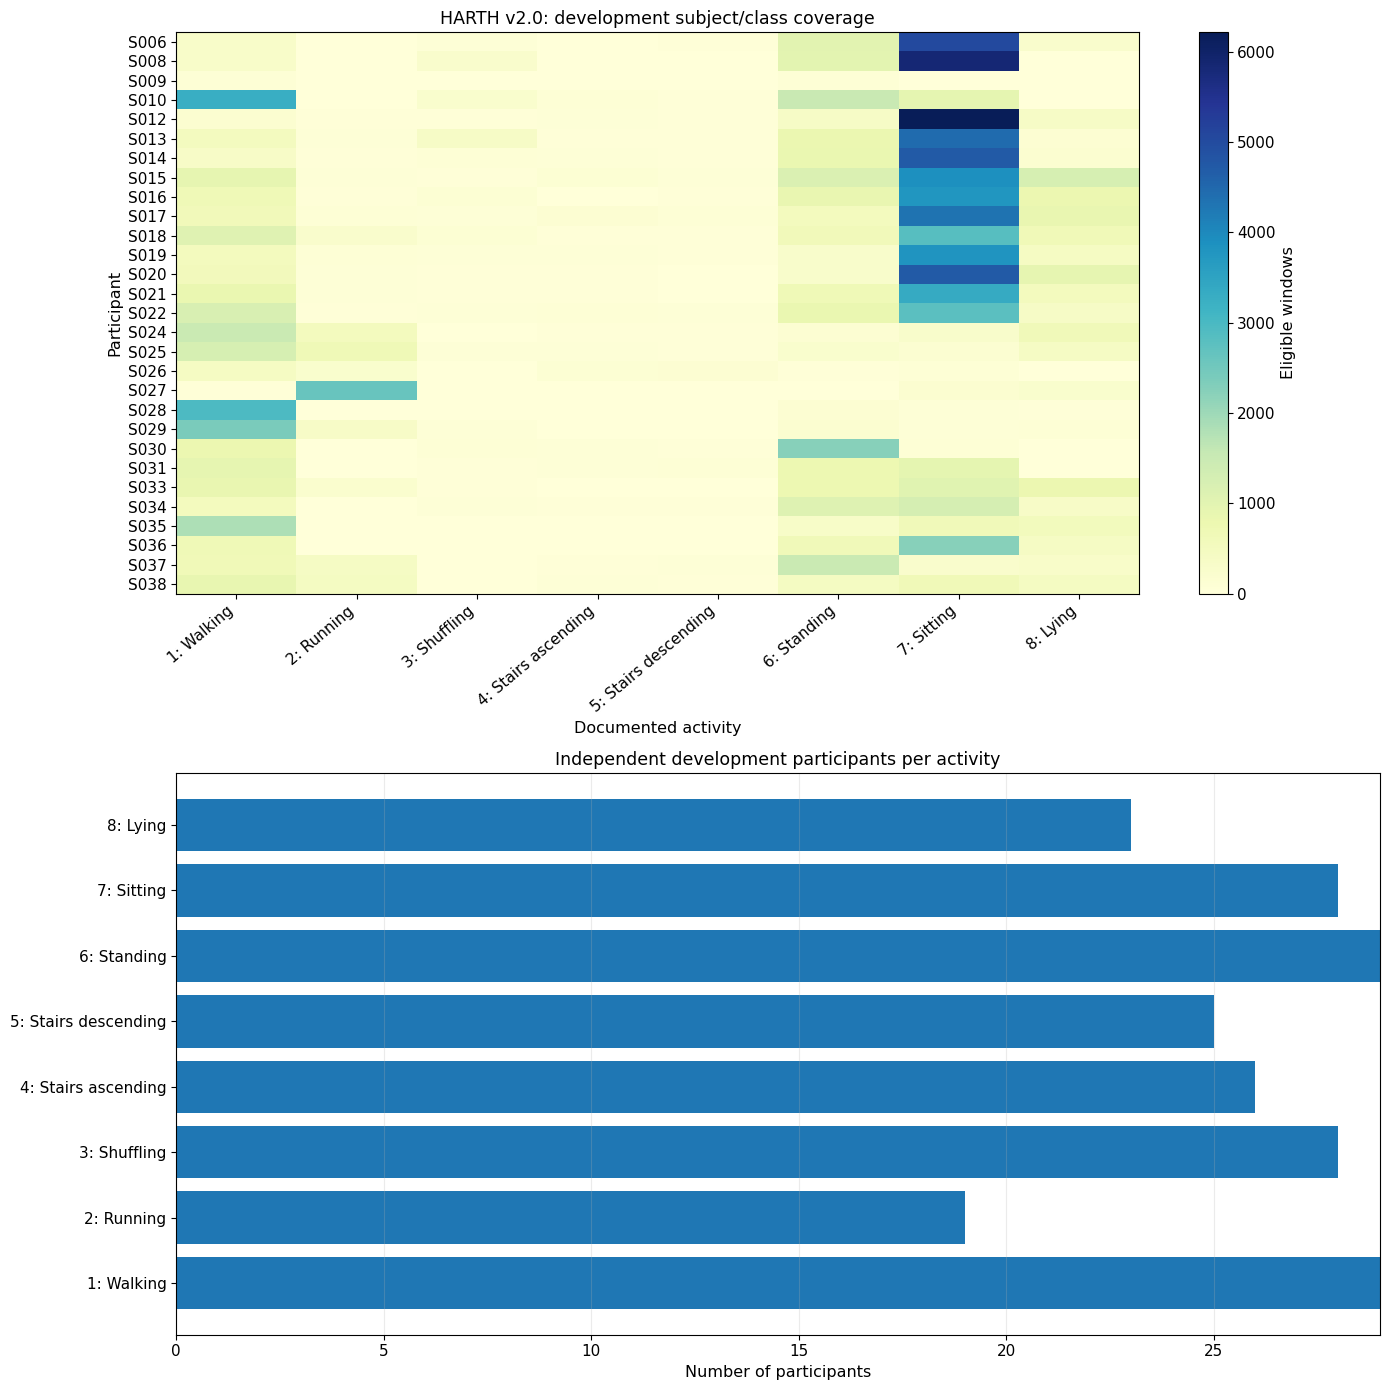

In [31]:
# ================ 05. Visualise Development Activity Support =================

# ----------------- 1. Visualise Participant Activity Support -----------------
fig, axes = plt.subplots(2, 1, figsize=(14, 14))
matrix = coverage.to_numpy()
heat = axes[0].imshow(matrix, aspect="auto", cmap="YlGnBu")
axes[0].set_xticks(np.arange(coverage.shape[1]), coverage.columns,
                   rotation=40, ha="right")
axes[0].set_yticks(np.arange(coverage.shape[0]), coverage.index)
axes[0].set(title="HARTH v2.0: development subject/class coverage",
            xlabel="Documented activity", ylabel="Participant")
fig.colorbar(heat, ax=axes[0], label="Eligible windows")

subject_support = (coverage > 0).sum(axis=0)

axes[1].barh(subject_support.index, subject_support.to_numpy())
axes[1].set(title="Independent development participants per activity",
            xlabel="Number of participants", xlim=(0, len(DEVELOPMENT_SUBJECTS)))
axes[1].grid(axis="x", alpha=0.25)
fig.tight_layout()
save_figure(fig, output_dir / "08_development_class_coverage.png")
plt.show()


**06. Research Quality Gate and Evaluation Boundary**

Verify the complete Development cohort, feature integrity, activity coverage and absence of reserved Test participants. This source audit supports the subsequent participant-disjoint Development experiments; it is not itself a predictive evaluation or a Test-scoring stage.

In [32]:
# ================== 06. Development Audit and Quality Gate ===================

# ----------------- 1. Verify Development and Fold Integrity ------------------
assert metadata["subject_id"].nunique() == 29
assert not (set(metadata["subject_id"]) & RESERVED_TEST)
assert features.shape == (len(metadata), 30)
assert np.isfinite(features.to_numpy()).all()
assert len(folds) == 5
assert sum(overview["eligible_windows"]) == len(metadata)
assert sum(overview["excluded_windows"]) == sum(excluded["excluded_windows"])

# ------------------------- 2. Quality Gate and Scope -------------------------
print("Full development-cohort audit: PASSED")
print("Reserved Test participants used: NO")
print("Group-independent model fitting completed: NO")
print("Next: review class coverage, choose grouped evaluation, then train.")

# ------------------------ 3. Save Development Audit Tables -------------------
inventory.to_csv(output_dir / "08_development_source_inventory.csv", index=False)
overview.to_csv(output_dir / "08_development_cohort_summary.csv", index=False)
excluded.to_csv(output_dir / "08_excluded_source_codes.csv", index=False)
coverage.rename_axis("subject_id").reset_index().to_csv(
    output_dir / "08_development_subject_class_coverage.csv", index=False
)
folds.to_csv(output_dir / "08_development_fold_class_audit.csv", index=False)
subject_support.rename_axis("activity").reset_index(name="supporting_subjects").to_csv(
    output_dir / "08_development_activity_subject_support.csv", index=False
)
print("Saved Development-only audit evidence in:", output_dir)

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="08")

Full development-cohort audit: PASSED
Reserved Test participants used: NO
Group-independent model fitting completed: NO
Next: review class coverage, choose grouped evaluation, then train.
Saved Development-only audit evidence in: /content/human-movement-intelligence/wearable_activity_recognition/output
